# Dasar-Dasar Pembelajaran Mesin

## Bagian 1, Bagian e: Pengujian Hipotesis 

## Tujuan: 
Setelah pembahasan ini, Anda diharapkan mampu: * Know difference between sebuah nol dan Hipotesis Alternatif
* Menuliskan hipotesis Anda sendiri untuk pengujian

In [1]:
# see https://ipython.readthedocs.io/en/stable/interactive/magics.html
%pylab inline

%config InlineBackend.figure_formats = ['svg']

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats 
import math

Populating the interactive namespace from numpy and matplotlib


## Hipotesis Nol

I claim yang I dapat use mystical abilities untuk predict outcome dari coin flips.

Anda don't pikirkan I dapat.

bagaimana dapat kita test ini?

kita do sebuah experiment dalam yang I call 100 coin flips. I get 57 right.

Am I special atau not?


--- 
### menentukan nol dan Hipotesis Alternatif

tulis nol dan alternatif hypotheses!

nol: 
alternatif:

---

**nol:** I'm not special; my benar rate dari flip prediction adalah 0.5. 
But even di bawah ini hipotesis, I dapat get 57 out dari 100 right. So did I get lucky (oleh random chance) atau am I mystical?

**alternatif:** My benar rate dari flip prediction adalah lebih besar dari 0.5.

 thing kita're measuring dari experiment, atau **test statistic**, adalah jumlah dari benar flip predictions out dari 100.

---

jika Hipotesis Nol adalah benar, test statistic adalah binomial distributed dengan parameter `n = 100` dan `p = 0.5`. yang adalah, jika kita repeated whole experiment many times, kita akan lihat such sebuah distribusi untuk semua hasil.

So jika Hipotesis Nol adalah benar, bagaimana likely adalah ini yang I got 57 atau lebih coin flips benar?

Sebelum kita periksa (really, Sebelum kita do experiment) kita decide apa akan convince us yang I memiliki ESP. choice dari sebuah cutoff at 5% probability adalah umum. yang adalah, jika kita akan only lihat data sebagai extreme sebagai kita've seen lebih kecil dari 5% dari time, kita'll say yang seems too unlikely dan kita akan conclude yang kita don't pikirkan Hipotesis Nol adalah benar.

---

kita memiliki two outcomes, one dengan probability (p) dan other dengan probability (1-p) dari happening (remember axioms dari probability?), so kita know [binomial](https://en.wikipedia.org/wiki/Binomial_distribution) [distribusi](http://mathworld.wolfram.com/BinomialDistribution.html) adalah [right tool untuk ini analysis](https://homepage.divms.uiowa.edu/~mbognar/applets/bin.html).

dalam case dari binomial distribusi, yang adalah discrete dan not too complicated mathematically, kita dapat just work out probability. But dalam general kita'll rely pada beberapa existing functionality. (dalam sebuah traditional statistics class, ini adalah part di mana kita'd turn untuk sebuah tabel dalam back dari book.)

In [10]:
from scipy.stats import binom
prob = 1 - binom.cdf(56, 100, 0.5)

print(str(round(prob*100, 1))+"%")

9.7%


 probability dari getting 57 atau lebih benar adalah tentang 9.7%. ini adalah lebih daripada 5%, so Kita dapat't reject nol dan conclude yang I (probably) don't memiliki mystical powers.

---

Conversely, Kita dapat gambar out apa 95% cutoff adalah beforehand.

--- 
### Latihan

temukan jumlah dari coin flips sebuah person akan perlu untuk guess correctly untuk us untuk believe they're clairvoyant.

---

In [11]:
from scipy.stats import binom
print(binom.ppf(0.95,100,0.5)+1)

59.0


yang means, one seharusnya get 59 tosses atau lebih untuk menjadi considered clairvoyant. dan kita akan say person memiliki predictive power dengan sebuah confidence level dari 95%.

---

## sebuah lebih spesifik Claim

So far so baik. apa jika instead I said, "I'm not perfect, but I dapat predict coin tosses 60% dari time. yang adalah still baik, yang adalah still valuable."

apa do kita do dalam ini case? Sure, Kita dapat do exactly apa kita did earlier dan ketika I predict 57 times, Kita dapat reject my claim.

But apa jika I say, "Wait sebuah minute. I said 60 dan I got 57, yang sounds pretty baik untuk me."

Interpretation:
> "I happened untuk memiliki sebuah poor guessing day, dan yang's mengapa my hasil aren't quite statistically significant!"

apa do kita say untuk yang? issue here adalah yang there adalah no longer sebuah tunggal Hipotesis Nol yang kita prove atau disprove. Instead, **kita memiliki two competing hypotheses**:
 * hipotesis sebuah: There adalah no predictive power
 * hipotesis B: There adalah sebuah 60% predictive power

setiap adalah sebuah normal curve, dengan one centered at 50% dan other at 60%.

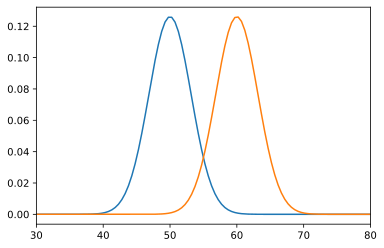

In [12]:
mu = 50
variance = 10
sigma = math.sqrt(variance)
x = np.linspace(1, 100, 200)
plt.plot(x,stats.norm.pdf(x, mu, sigma))

mu = 60
variance = 10
sigma = math.sqrt(variance)
x = np.linspace(1, 100, 200)
plt.plot(x,stats.norm.pdf(x, mu, sigma))

plt.xlim(30,80)
plt.show()

**dan 57 benar guesses falls dalam 95% confidence dari both curves:**

In [13]:
print (1 - binom.cdf(57, 100, 0.5))
print (binom.cdf(57, 100, 0.6))

0.06660530960360678
0.3032601298434453


apa sekarang? There just isn't enough data untuk achieve sebuah confidence dari 95%. There adalah few things Kita dapat do.

### 1) Decrease confidence


Since kita memiliki sebuah claim at 50 dan 60, Kita dapat pick mid-point, yang adalah 55. Kita dapat say jika I dapat predict di atas 55, kemudian I memiliki predictive power. ini akan rata-rata yang kita memiliki decreased kita confidence level.

In [14]:
print (1 - binom.cdf(55, 100, 0.5))
print (binom.cdf(54, 100, 0.6))

0.1356265120369171
0.13109045261974842


** At sebuah 87% percent confidence level, Kita dapat say yang I memiliki beberapa predictive power, since I got 57 tosses benar.**

Not ideal; kita picked sebuah jumlah, yang adalah prone untuk bias, rather daripada sebuah confidence interval.

### 2) menjadi biased

But ini adalah not neccessary yang kita bias two hypotheses equally dan pick midpoint way kita did. cut-off point dapat menjadi anywhere. Currently, kita error margins adalah even. chance yang someone memiliki predictive power dan kita say no adalah 13% dan chance yang someone memiliki no power dan kita say they do adalah juga 13%. sebagai kita change cutoff, one error goes down dan other goes way up.

untuk example, jika kita stuck dengan asli 95% pada sebuah coin being fair:

In [15]:
binom.ppf(0.95, 100, 0.5) #ini adalah inverse dari cdf fungsi above

58.0

kemudian kita cutff adalah 58. kita two errors akan menjadi:

In [16]:
print (1-binom.cdf(58, 100, 0.5))
print (binom.cdf(58, 100, 0.6))

0.04431304005703374
0.3774673238778277


5% chance someone memiliki no power dan kita say they do. But sebuah 38% chance someone memiliki predictive power dan kita say no. yang depending pada problem might menjadi exactly apa kita want. ini two tipe dari errors adalah called Type I dan Type II. dan kita memiliki choice dari biasing against one atau other. 

### 3) Increase sample Ukuran

 best scenario though adalah untuk increase sample Ukuran. Imagine apa happens kita did 1000 tosses instead dari 100.

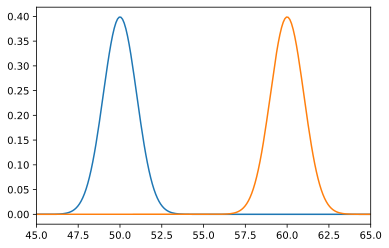

In [17]:
mu = 50
variance = 1
sigma = math.sqrt(variance)
x = np.linspace(1, 100, 1000)
plt.plot(x,stats.norm.pdf(x, mu, sigma))

mu = 60
variance = 1
sigma = math.sqrt(variance)
x = np.linspace(1, 100, 1000)
plt.plot(x,stats.norm.pdf(x, mu, sigma))

plt.xlim(45,65)
plt.show()

 two normal curves adalah completely seperated sekarang.

In [18]:
print (binom.ppf(0.95,1000,0.5))
print (binom.ppf(0.05,1000,0.6))

526.0
574.0


---

### Latihan

apa adalah kita errors sekarang?

---

In [19]:
print (1-binom.cdf(550, 1000, 0.5))
print (binom.cdf(550, 1000, 0.6))

0.0006958707972113398
0.0007412028990062971


**dengan sebuah cutoff dari 550, both kita errors come down untuk di bawah 0.1%.**